# 04_Scorecard — Sélection, régression logistique et grille de score

**Projet :** Credit Risk Scorecard · **Phase 3** — sous-ensembles 3d et 3e · Données : Home Credit Default Risk (Kaggle).

- Sélection, régression et mise à l'échelle sont réalisées par `scripts/train_scorecard.py` ; ce notebook relit les artefacts et utilise `score_frame()` pour scorer le train. Les scores de validation sont lus dans `models/scorecard_valid_scores.parquet`.
- Échantillons : **train** (ajustement) et **validation** (contrôle de performance uniquement). Le test est scellé (D15) et n'est pas lu.
- Mise à l'échelle (D21) : 600 points pour des odds 50:1 (bons:mauvais), PDO = 20 ; **score élevé = risque faible**.
- Figures écrites : `output/04_*.png`.

In [1]:
# --- Setup : vérification du répertoire de travail, connexion DuckDB en lecture seule ---
import os
import sys
from pathlib import Path

cwd = Path.cwd()
# Jupyter / VS Code lancent le noyau dans notebooks/ : on remonte d'un niveau si c'est le cas.
if cwd.name == "notebooks" and (cwd.parent / "scripts" / "config.py").is_file():
    os.chdir(cwd.parent)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name != "credit-risk-scorecard" or not (PROJECT_ROOT / "scripts" / "config.py").is_file():
    raise RuntimeError(
        f"Répertoire de travail inattendu : {PROJECT_ROOT}. "
        "Lancer le notebook depuis la racine credit-risk-scorecard/ (ou depuis notebooks/)."
    )
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

import hashlib

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from build_feature_catalog import CAND, CATALOG
from config import DB_PATH, FIGURES_DIR
from make_splits import load_split

if not DB_PATH.exists():
    raise FileNotFoundError(f"{DB_PATH} introuvable.")
con = duckdb.connect(str(DB_PATH), read_only=True)

# Style des figures : identique aux notebooks 00 et 01
BLUE, INK, INK2, GRID, GREY = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#a3a29d"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9,
})
print("Racine :", PROJECT_ROOT.name)
print(f"Python {sys.version.split()[0]} · duckdb {duckdb.__version__} · pandas {pd.__version__} · matplotlib {matplotlib.__version__}")

Racine : credit-risk-scorecard
Python 3.13.15 · duckdb 1.5.5 · pandas 3.0.6 · matplotlib 3.11.2


In [2]:
# --- Artefacts produits par scripts/train_scorecard.py et fonctions réutilisées ---
import json

from train_scorecard import (
    IV_TABLE, METRICS_JSON, SCORECARD_TABLE, VALID_SCORES, discrimination, ks_curve, score_bands, score_frame,
)

missing = [p.name for p in (IV_TABLE, METRICS_JSON, SCORECARD_TABLE, VALID_SCORES) if not p.exists()]
if missing:
    raise FileNotFoundError(f"Artefacts absents : {missing}. Lancer d'abord scripts/train_scorecard.py.")
iv = pd.read_csv(IV_TABLE)
sc = pd.read_csv(SCORECARD_TABLE)
metrics = json.loads(METRICS_JSON.read_text(encoding="utf-8"))
variables = metrics["variables"]
print(f"Grille : {metrics['n_vars']} variables · {len(sc)} classes · score de {metrics['score_range']['min']} "
      f"à {metrics['score_range']['max']} points")

Grille : 17 variables · 137 classes · score de 439 à 660 points


## 1. Entonnoir de sélection (D18 à D20)

Ordre des filtres : IV ≥ 0,02 → corrélation des WoE ≤ 0,7 (IV le plus élevé conservé) → VIF ≤ 5 → 20 variables au plus → p ≤ 0,05 et coefficient de signe cohérent.

etape,variables
Candidates (D16),200
"IV ≥ 0,02 (D18)",82
"Corrélation ≤ 0,7 (D19)",41
VIF ≤ 5 (D19),41
Plafond 20 (D19),20
"p ≤ 0,05 et signe (D20)",17


,variables
exclusion_reason,
iv_low,118
corr_with_X,41
cap20,21
pvalue,2
sign,1


**Variables retirées lors de la régression**

variable,iv,exclusion_reason
APP_AGE_YEARS,0.0895,sign
NAME_INCOME_TYPE,0.0548,pvalue
AMT_GOODS_PRICE,0.0542,pvalue


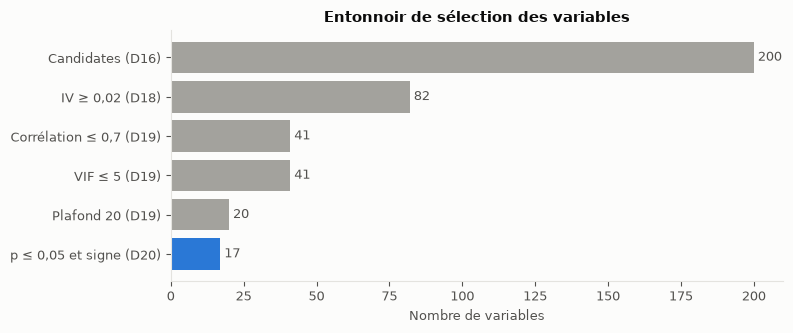

In [3]:
fu = metrics["funnel"]
steps = pd.DataFrame({
    "etape": ["Candidates (D16)", "IV ≥ 0,02 (D18)", "Corrélation ≤ 0,7 (D19)", "VIF ≤ 5 (D19)",
              "Plafond 20 (D19)", "p ≤ 0,05 et signe (D20)"],
    "variables": [fu["candidates"], fu["iv_ge_0_02"], fu["after_corr"], fu["after_vif"], fu["after_cap20"], fu["final"]],
})
display(steps.style.hide(axis="index"))

reasons = (iv.loc[iv["status"].eq("excluded"), "exclusion_reason"]
           .str.replace(r"^corr_with_.*", "corr_with_X", regex=True).value_counts().rename("variables"))
display(reasons.to_frame())
late = iv[iv["exclusion_reason"].isin(["pvalue", "sign"])]
display(Markdown("**Variables retirées lors de la régression**"))
display(late[["variable", "iv", "exclusion_reason"]].style.format({"iv": "{:.4f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(steps["etape"][::-1], steps["variables"][::-1], color=[BLUE] + [GREY] * 5)
for y_, v in enumerate(steps["variables"][::-1]):
    ax.text(v, y_, f" {v}", va="center", color=INK2)
ax.set_xlabel("Nombre de variables")
ax.set_title("Entonnoir de sélection des variables")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_selection_funnel.png", dpi=150)
plt.show()

## 2. Régression logistique sur les WoE (D20)

Régression non pondérée (`statsmodels`) de `TARGET` (1 = défaut) sur les WoE du train. Avec la convention d'optbinning (WoE élevé = risque faible), tous les coefficients doivent être **négatifs**.
L'amplitude de points (max − min) mesure le poids effectif de chaque variable dans le score.

Intercept : -2.4352 · coefficients tous négatifs : True · p-valeur maximale : 4.42e-04 · VIF maximal : 2.05


variable,iv,coefficient,p_valeur,vif,points_min,points_max,amplitude
APP_EXT_SOURCE_MEAN,0.6287,-0.6866,0.00e+00,2.05,5,65,60
EXT_SOURCE_3,0.3335,-0.2165,6.69e-31,1.82,26,39,13
EXT_SOURCE_1,0.1501,-0.1575,2.32e-10,1.28,30,38,8
APP_EMPLOYED_YEARS,0.1163,-0.3552,4.35e-36,1.34,29,40,11
BUR_YEARS_SINCE_LAST_CREDIT,0.0888,-0.2870,1.03e-21,1.20,28,36,8
INS_MAX_DAYS_LATE_12M,0.0802,-0.4036,3.63e-37,1.31,23,35,12
CC_MAX_UTILIZATION_12M,0.0790,-0.3897,1.24e-21,1.93,24,37,13
OCCUPATION_TYPE,0.0780,-0.3713,3.81e-30,1.25,28,37,9
APP_CREDIT_GOODS_RATIO,0.0733,-0.6243,3.34e-98,1.02,24,37,13
PREV_MEAN_CREDIT_APPLICATION_RATIO,0.0726,-0.4350,7.95e-44,1.09,26,38,12


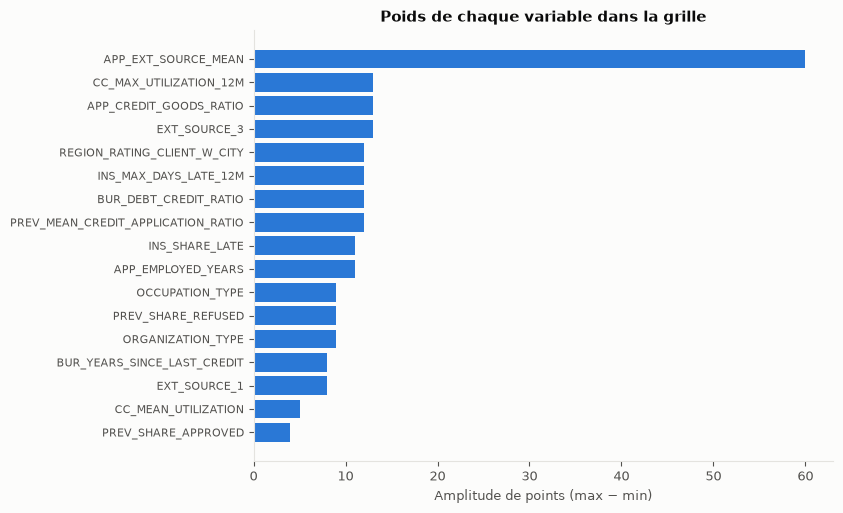

In [4]:
coef = pd.DataFrame({
    "variable": variables,
    "iv": [float(iv.loc[iv["variable"].eq(v), "iv"].iloc[0]) for v in variables],
    "coefficient": [metrics["coefficients"][v] for v in variables],
    "p_valeur": [metrics["pvalues"][v] for v in variables],
    "vif": [metrics["vif"][v] for v in variables],
})
amp = sc.groupby("variable")["points"].agg(points_min="min", points_max="max")
coef = coef.join(amp, on="variable")
coef["amplitude"] = coef["points_max"] - coef["points_min"]
print(f"Intercept : {metrics['coefficients']['const']:.4f} · coefficients tous négatifs : "
      f"{bool((coef['coefficient'] < 0).all())} · p-valeur maximale : {coef['p_valeur'].max():.2e} · "
      f"VIF maximal : {coef['vif'].max():.2f}")
display(coef.style.format({"iv": "{:.4f}", "coefficient": "{:.4f}", "p_valeur": "{:.2e}", "vif": "{:.2f}"})
        .hide(axis="index"))

c = coef.sort_values("amplitude")
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.barh(c["variable"], c["amplitude"], color=BLUE)
ax.set_xlabel("Amplitude de points (max − min)")
ax.set_title("Poids de chaque variable dans la grille")
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_points_range.png", dpi=150)
plt.show()

## 3. Grille de score (D21)

`points = round(−factor × (coefficient × WoE + intercept / n) + offset / n)`, avec factor = PDO / ln 2 et offset = 600 − factor × ln 50 ; l'intercept est réparti à parts égales entre les n variables.
La classe « Missing » reçoit les points de son WoE empirique (WoE 0 si aucun manquant au train).

In [5]:
s = metrics["scaling"]
print(f"factor = {s['factor']:.4f} · offset = {s['offset']:.4f} · n = {metrics['n_vars']}")
pd.set_option("display.max_rows", 300)
display(sc.style.format({"count": "{:,}", "count_pct": "{:.4f}", "event_rate": "{:.4f}", "woe": "{:.4f}"})
        .hide(axis="index"))

factor = 28.8539 · offset = 487.1229 · n = 17


variable,bin,count,count_pct,event_rate,woe,points
APP_EXT_SOURCE_MEAN,"(-inf, 0.24)","11,641",0.0541,0.2656,-1.4155,5
APP_EXT_SOURCE_MEAN,"[0.24, 0.33)","16,151",0.0750,0.1805,-0.9199,15
APP_EXT_SOURCE_MEAN,"[0.33, 0.37)","11,451",0.0532,0.1388,-0.6069,21
APP_EXT_SOURCE_MEAN,"[0.37, 0.43)","20,995",0.0975,0.1114,-0.3556,26
APP_EXT_SOURCE_MEAN,"[0.43, 0.47)","20,885",0.0970,0.0847,-0.0518,32
APP_EXT_SOURCE_MEAN,"[0.47, 0.50)","11,217",0.0521,0.0686,0.1766,36
APP_EXT_SOURCE_MEAN,"[0.50, 0.52)","11,222",0.0521,0.0665,0.2096,37
APP_EXT_SOURCE_MEAN,"[0.52, 0.54)","11,235",0.0522,0.0586,0.3447,40
APP_EXT_SOURCE_MEAN,"[0.54, 0.56)","12,369",0.0575,0.0535,0.4402,42
APP_EXT_SOURCE_MEAN,"[0.56, 0.59)","18,566",0.0862,0.0430,0.6692,46


## 4. Scores du train et de la validation

Train : recalculé par `score_frame()` à partir des artefacts. Validation : scores enregistrés par le script, joints à `TARGET`.
Les métriques recalculées doivent être identiques à celles de `scorecard_metrics.json`.

In [6]:
train = load_split(con, "train", ["SK_ID_CURR", "TARGET", *variables])
s_tr = score_frame(train).assign(TARGET=train["TARGET"].to_numpy())
valid_y = load_split(con, "valid", ["SK_ID_CURR", "TARGET"])
s_va = pd.read_parquet(VALID_SCORES).merge(valid_y, on="SK_ID_CURR", how="inner", validate="one_to_one")
if len(s_va) != metrics["n_valid"]:
    raise RuntimeError("Les scores de validation ne couvrent pas tout l'échantillon.")

m_tr, m_va = discrimination(s_tr["TARGET"], s_tr["score"]), discrimination(s_va["TARGET"], s_va["score"])
for name, m in (("train", m_tr), ("valid", m_va)):
    for k in ("auc", "gini", "ks"):
        if not np.isclose(m[k], metrics["metrics"][name][k], atol=1e-12):
            raise RuntimeError(f"{name} {k} recalculé ≠ scorecard_metrics.json")
perf = pd.DataFrame({"train": m_tr, "validation": m_va}).T
perf["effectif"] = [len(s_tr), len(s_va)]
display(perf.style.format({"auc": "{:.4f}", "gini": "{:.4f}", "ks": "{:.4f}", "effectif": "{:,}"}))
gap = m_tr["auc"] - m_va["auc"]
print(f"Écart d'AUC train − validation : {gap:.4f} (seuil 0,02) → {'conforme' if gap < 0.02 else 'NON conforme'}")

,auc,gini,ks,effectif
train,0.7544,0.5087,0.3810,"215,257"
validation,0.7529,0.5059,0.3808,"46,127"


Écart d'AUC train − validation : 0.0014 (seuil 0,02) → conforme


## 5. Distribution des scores : bons et mauvais payeurs (validation)

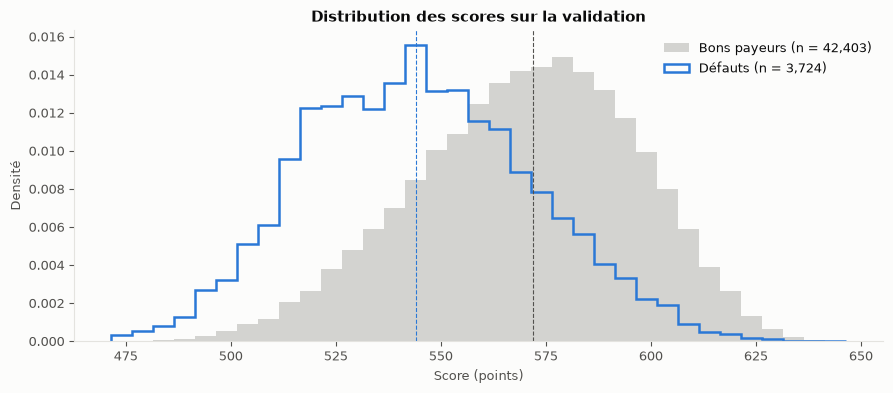

Score médian : bons payeurs 572 · défauts 544


In [7]:
good = s_va.loc[s_va["TARGET"].eq(0), "score"]
bad = s_va.loc[s_va["TARGET"].eq(1), "score"]
bins = np.arange(s_va["score"].min() - 0.5, s_va["score"].max() + 5, 5)
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(good, bins=bins, density=True, histtype="stepfilled", color=GREY, alpha=0.45, label=f"Bons payeurs (n = {len(good):,})")
ax.hist(bad, bins=bins, density=True, histtype="step", color=BLUE, lw=1.8, label=f"Défauts (n = {len(bad):,})")
ax.axvline(good.median(), color=INK2, lw=0.8, ls="--")
ax.axvline(bad.median(), color=BLUE, lw=0.8, ls="--")
ax.set_xlabel("Score (points)")
ax.set_ylabel("Densité")
ax.set_title("Distribution des scores sur la validation")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_score_distribution.png", dpi=150)
plt.show()
print(f"Score médian : bons payeurs {good.median():.0f} · défauts {bad.median():.0f}")

## 6. Courbes ROC et KS (train et validation)

KS = écart maximal entre la répartition cumulée des défauts et celle des bons payeurs, en balayant le score par ordre croissant.

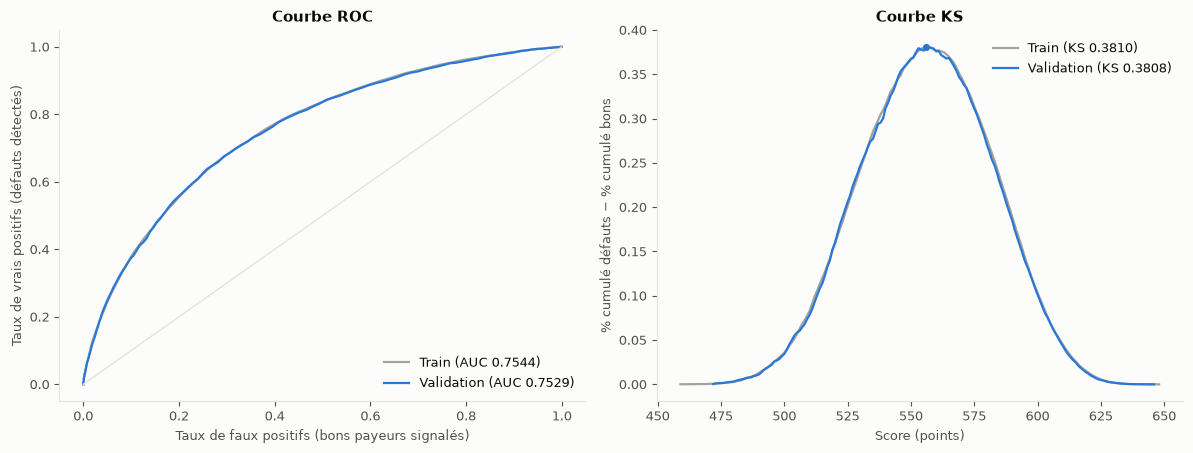

KS validation atteint à 556 points


In [8]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for frame, label, color, m in ((s_tr, "Train", GREY, m_tr), (s_va, "Validation", BLUE, m_va)):
    fpr, tpr, _ = roc_curve(frame["TARGET"], -frame["score"])
    axes[0].plot(fpr, tpr, color=color, lw=1.6, label=f"{label} (AUC {m['auc']:.4f})")
    k = ks_curve(frame["TARGET"], frame["score"])
    axes[1].plot(k["score"], k["gap"], color=color, lw=1.6, label=f"{label} (KS {m['ks']:.4f})")
    i = k["gap"].idxmax()
    axes[1].plot(k.loc[i, "score"], k.loc[i, "gap"], "o", color=color, ms=4)
axes[0].plot([0, 1], [0, 1], color=GRID, lw=1)
axes[0].set_xlabel("Taux de faux positifs (bons payeurs signalés)")
axes[0].set_ylabel("Taux de vrais positifs (défauts détectés)")
axes[0].set_title("Courbe ROC")
axes[1].set_xlabel("Score (points)")
axes[1].set_ylabel("% cumulé défauts − % cumulé bons")
axes[1].set_title("Courbe KS")
for ax in axes:
    ax.legend(frameon=False, loc="lower right" if ax is axes[0] else "upper right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_roc_ks.png", dpi=150)
plt.show()
ks_va = ks_curve(s_va["TARGET"], s_va["score"])
print(f"KS validation atteint à {ks_va.loc[ks_va['gap'].idxmax(), 'score']:.0f} points")

## 7. Taux de défaut par tranche de score (validation)

Déciles du score de validation : taux de défaut observé et PD moyenne du logit. Une grille bien ordonnée donne un taux de défaut décroissant d'une tranche à l'autre.

tranche,n,defauts,taux_defaut,score_min,score_max,pd_moyenne
"(471.999, 531.0]","4,727","1,250",26.44%,472,531,26.45%
"(531.0, 545.0]","4,851",712,14.68%,532,545,14.54%
"(545.0, 554.0]","4,323",454,10.50%,546,554,10.30%
"(554.0, 563.0]","5,101",384,7.53%,555,563,7.70%
"(563.0, 570.0]","4,408",264,5.99%,564,570,5.93%
"(570.0, 577.0]","4,532",208,4.59%,571,577,4.69%
"(577.0, 584.0]","4,528",167,3.69%,578,584,3.71%
"(584.0, 592.0]","4,595",120,2.61%,585,592,2.88%
"(592.0, 602.0]","4,556",99,2.17%,593,602,2.12%
"(602.0, 646.0]","4,506",66,1.46%,603,646,1.32%


Taux de défaut strictement décroissant d'une tranche à l'autre : True


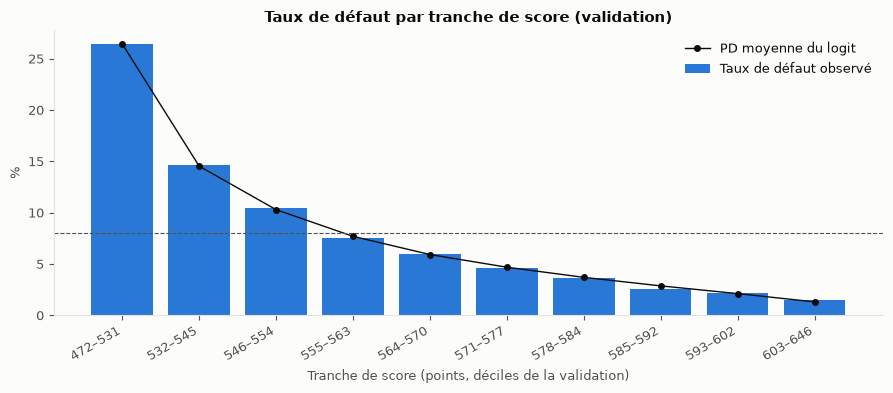

In [9]:
bands = score_bands(s_va["score"], s_va["TARGET"], s_va["pd"], q=10)
bands["tranche"] = bands["tranche"].astype(str)
display(bands.style.format({"n": "{:,}", "defauts": "{:,}", "taux_defaut": "{:.2%}", "pd_moyenne": "{:.2%}"})
        .hide(axis="index"))
monotone_bands = bool((bands["taux_defaut"].diff().dropna() < 0).all())
print(f"Taux de défaut strictement décroissant d'une tranche à l'autre : {monotone_bands}")

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(bands))
ax.bar(x, 100 * bands["taux_defaut"], color=BLUE, label="Taux de défaut observé")
ax.plot(x, 100 * bands["pd_moyenne"], "o-", color=INK, ms=4, lw=1, label="PD moyenne du logit")
ax.axhline(100 * s_va["TARGET"].mean(), color=INK2, lw=0.8, ls="--")
ax.set_xticks(x)
ax.set_xticklabels([f"{a}–{b}" for a, b in zip(bands["score_min"], bands["score_max"])], rotation=30, ha="right")
ax.set_xlabel("Tranche de score (points, déciles de la validation)")
ax.set_ylabel("%")
ax.set_title("Taux de défaut par tranche de score (validation)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_score_bands.png", dpi=150)
plt.show()

## 8. Synthèse

In [10]:
flags = metrics["iv_flagged_gt_0_5"]
top_amp = coef.sort_values("amplitude", ascending=False).head(3)
mc = metrics["mapping_check"]
display(Markdown(f"""
**Constats (train {metrics['n_train']:,} demandes ; validation {metrics['n_valid']:,})**
- Sélection : {fu['candidates']} candidates → {fu['final']} variables retenues ; coefficients tous négatifs
  (signe cohérent avec la convention WoE) ; p-valeur maximale {coef['p_valeur'].max():.2e} ; VIF maximal {coef['vif'].max():.2f}.
- Variables les plus influentes (amplitude de points) : {", ".join(f"`{r.variable}` ({r.amplitude} pts)" for r in top_amp.itertuples())}.
- Performance : AUC {m_tr['auc']:.4f} (train) et {m_va['auc']:.4f} (validation), Gini {m_va['gini']:.4f}, KS {m_va['ks']:.4f}
  sur la validation ; écart d'AUC {gap:.4f}, {'sous le' if gap < 0.02 else 'au-dessus du'} seuil de 0,02.
- Ordonnancement : taux de défaut de {100 * bands['taux_defaut'].iloc[0]:.2f} % dans la tranche la plus basse
  à {100 * bands['taux_defaut'].iloc[-1]:.2f} % dans la plus haute ; décroissance stricte : {'oui' if monotone_bands else 'non'}.
- Échelle : PD de {100 * mc['pd_at_base']:.2f} % à 600 points, odds doublées tous les 20 points ; écart moyen entre la PD implicite
  du score arrondi et la PD du logit : {mc['mean_abs_pd_diff_valid']:.5f} (maximal {mc['max_abs_pd_diff_valid']:.5f}).
- IV > 0,5 (D18) : {", ".join(f"`{v}`" for v in flags) or "aucune"} — à examiner lors de l'ablation `EXT_SOURCE` (Phase 4).
"""))


**Constats (train 215,257 demandes ; validation 46,127)**
- Sélection : 200 candidates → 17 variables retenues ; coefficients tous négatifs
  (signe cohérent avec la convention WoE) ; p-valeur maximale 4.42e-04 ; VIF maximal 2.05.
- Variables les plus influentes (amplitude de points) : `APP_EXT_SOURCE_MEAN` (60 pts), `EXT_SOURCE_3` (13 pts), `CC_MAX_UTILIZATION_12M` (13 pts).
- Performance : AUC 0.7544 (train) et 0.7529 (validation), Gini 0.5059, KS 0.3808
  sur la validation ; écart d'AUC 0.0014, sous le seuil de 0,02.
- Ordonnancement : taux de défaut de 26.44 % dans la tranche la plus basse
  à 1.46 % dans la plus haute ; décroissance stricte : oui.
- Échelle : PD de 1.96 % à 600 points, odds doublées tous les 20 points ; écart moyen entre la PD implicite
  du score arrondi et la PD du logit : 0.00202 (maximal 0.03842).
- IV > 0,5 (D18) : `APP_EXT_SOURCE_MEAN` — à examiner lors de l'ablation `EXT_SOURCE` (Phase 4).


In [11]:
con.close()